# 🚗 Parking Space Occupancy Detector

## 📌 Table of Contents

1. Project Introduction

2. Problem Statement

3. Objectives

4. Real World Applications

5. Technology Stack

6. Required Libraries

7. Import Libraries

8. Google Drive Setup

9. Dataset Upload

10. Dataset Extraction

11. Dataset Structure Analysis

12. Exploratory Data Analysis (EDA)

13. Understanding XML Annotations

14. Understanding Parking CSV File

15. Class Analysis

16. Image Visualization

17. XML to YOLO Format Conversion

18. YOLO Dataset Preparation

19. Train / Validation Split

20. Dataset Verification

21. Create dataset.yaml

22. Load YOLOv8 Pretrained Model

23. Model Training

24. Training Visualization

25. Model Evaluation

26. Performance Metrics

27. Test on Sample Images

28. Prediction Visualization

29. Save Best Model

30. Download Trained Model

31. Streamlit Web Application Development

32. Image Upload Module

33. Parking Space Detection

34. Occupancy Status Prediction

35. Confidence Score Visualization

36. Interactive Dashboard

37. Prediction Report Generation

38. Project Folder Structure

39. Results

40. Advantages

41. Limitations

42. Future Improvements

43. Conclusion

In [3]:
!pip install -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.2 MB/s eta 0:00:00


# Import Libraries

In [4]:
import os
import cv2
import yaml
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from glob import glob
from tqdm import tqdm
from PIL import Image
from xml.etree import ElementTree as ET

from sklearn.model_selection import train_test_split

from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


# Extract File

In [5]:
import zipfile
import os
import shutil

zip_path = "/content/sample_data/archive (1).zip"
extract_path = "/content/Parking_Dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")
print("Extracted Folder:", extract_path)

Dataset Extracted Successfully!
Extracted Folder: /content/Parking_Dataset


# Dataset Structure


In [6]:
dataset_path = "/content/Parking_Dataset"

print("=" * 60)
print("DATASET STRUCTURE")
print("=" * 60)

for root, dirs, files in os.walk(dataset_path):

    level = root.replace(dataset_path, "").count(os.sep)

    indent = " " * 4 * level

    print(f"{indent} {os.path.basename(root)}")

    sub_indent = " " * 4 * (level + 1)

    for file in files[:5]:
        print(f"{sub_indent} {file}")

DATASET STRUCTURE
 Parking_Dataset
     parking.csv
     annotations.xml
     boxes
         31.png
         28.png
         6.png
         10.png
         21.png
     images
         31.png
         28.png
         6.png
         10.png
         21.png


# Show Random Images

Total Images Found : 60


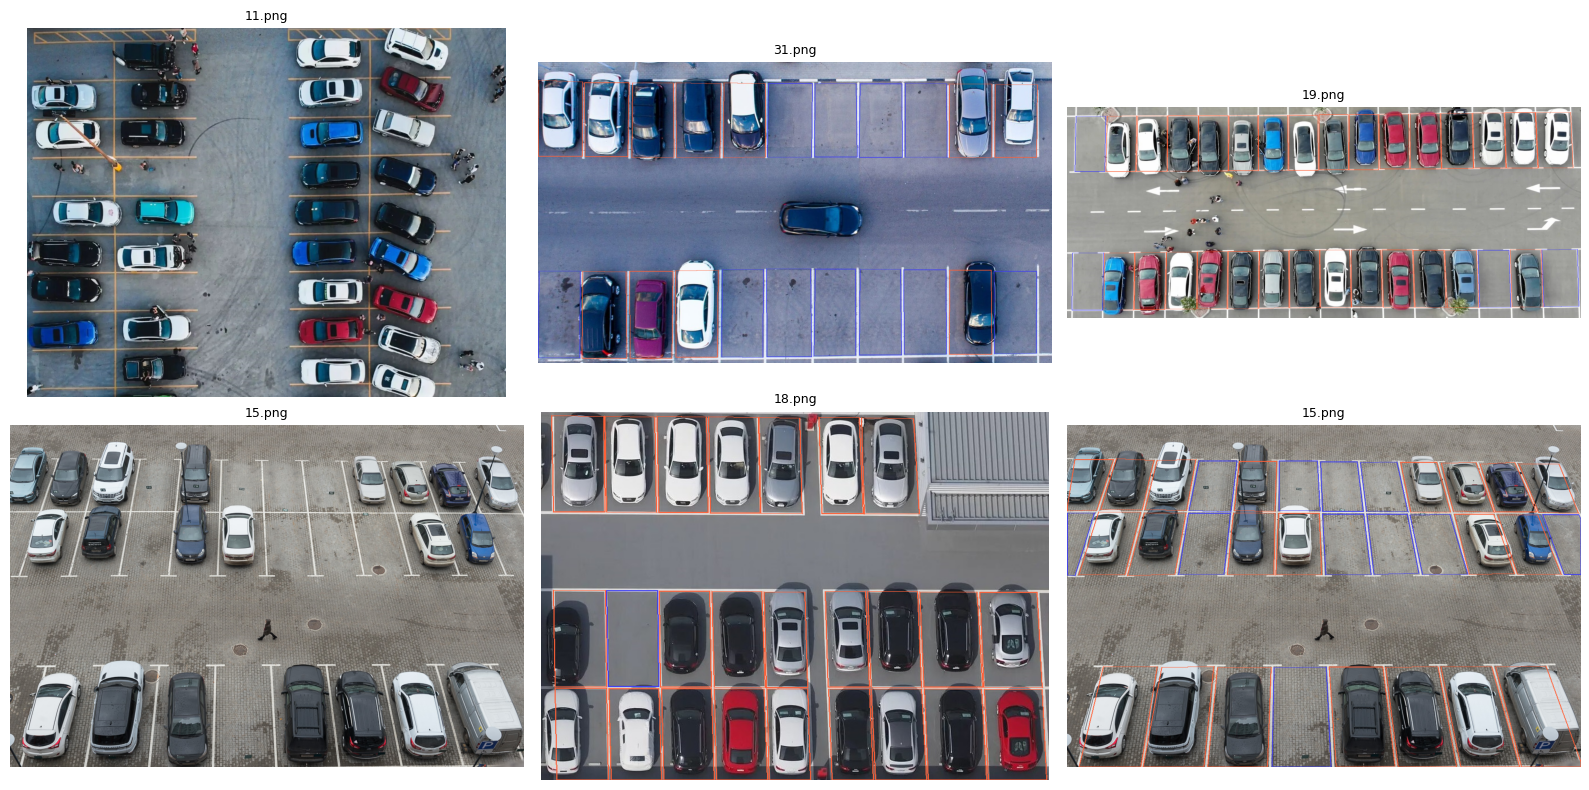

In [7]:
import random
import matplotlib.pyplot as plt
from PIL import Image

image_files = []

for root, dirs, files in os.walk(dataset_path):

    for file in files:

        if file.lower().endswith((".jpg",".jpeg",".png",".bmp")):

            image_files.append(os.path.join(root,file))

print("Total Images Found :", len(image_files))

sample_images = random.sample(image_files, min(6, len(image_files)))

plt.figure(figsize=(16,8))

for i, img_path in enumerate(sample_images):

    img = Image.open(img_path)

    plt.subplot(2,3,i+1)

    plt.imshow(img)

    plt.title(os.path.basename(img_path), fontsize=9)

    plt.axis("off")

plt.tight_layout()

plt.show()

# Image Information

In [8]:
from PIL import Image

img = Image.open(sample_images[0])

print("="*40)
print("🖼 IMAGE INFORMATION")
print("="*40)

print("Filename :", os.path.basename(sample_images[0]))
print("Size     :", img.size)
print("Mode     :", img.mode)
print("Format   :", img.format)

🖼 IMAGE INFORMATION
Filename : 11.png
Size     : (1353, 1041)
Mode     : RGB
Format   : JPEG


# Read CSV

In [9]:
csv_path = "/content/Parking_Dataset/parking.csv"

df = pd.read_csv(csv_path)

print(df.head())

print("\nShape :", df.shape)

print("\nColumns :")

print(df.columns)

   id         image         mask
0   0  images/0.png  boxes/0.png
1   1  images/1.png  boxes/1.png
2   2  images/2.png  boxes/2.png
3   3  images/3.png  boxes/3.png
4   4  images/4.png  boxes/4.png

Shape : (33, 3)

Columns :
Index(['id', 'image', 'mask'], dtype='object')


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      33 non-null     int64 
 1   image   33 non-null     object
 2   mask    33 non-null     object
dtypes: int64(1), object(2)
memory usage: 924.0+ bytes


# Missing Values

In [11]:
df.isnull().sum()

,0
id,0
image,0
mask,0


# XML Analysis

# XML Structure

In [12]:
import xml.etree.ElementTree as ET

xml_path = "/content/Parking_Dataset/annotations.xml"

tree = ET.parse(xml_path)
root = tree.getroot()

images = root.findall("image")

print("Total Annotated Images :", len(images))

print("="*60)

for img in images[:3]:

    print("Image Name :", img.attrib.get("name"))
    print("Width      :", img.attrib.get("width"))
    print("Height     :", img.attrib.get("height"))

    print("Parking Slots :", len(img.findall("polygon")))

    print("-"*50)

Total Annotated Images : 30
Image Name : images/0.png
Width      : 1200
Height     : 621
Parking Slots : 28
--------------------------------------------------
Image Name : images/1.png
Width      : 650
Height     : 487
Parking Slots : 38
--------------------------------------------------
Image Name : images/10.png
Width      : 2560
Height     : 1820
Parking Slots : 20
--------------------------------------------------


# First Parking Polygon

In [13]:
first_image = images[0]

polygon = first_image.find("polygon")

print("Label :", polygon.attrib.get("label"))

print()

print("Points :")

print(polygon.attrib.get("points"))

Label : free_parking_space

Points :
54.80,9.10;137.90,7.60;141.12,204.87;55.80,205.70


# Count Total Parking Slots

In [14]:
total_slots = 0

for img in images:

    total_slots += len(img.findall("polygon"))

print("Total Parking Slots :", total_slots)

Total Parking Slots : 903


# Visualize Parking Polygons

Exists : True
cv2 Output : [[[128 134 129]
  [132 138 133]
  [134 140 135]
  ...
  [250 248 248]
  [243 241 241]
  [255 254 254]]

 [[137 143 138]
  [145 151 146]
  [146 152 147]
  ...
  [255 255 255]
  [251 251 251]
  [250 250 250]]

 [[103 107 102]
  [ 82  86  81]
  [ 69  73  68]
  ...
  [244 249 248]
  [238 244 243]
  [237 243 242]]

 ...

 [[167 175 175]
  [159 167 166]
  [147 155 155]
  ...
  [210 225 221]
  [213 230 227]
  [213 230 227]]

 [[ 72  79  76]
  [ 65  72  69]
  [ 40  47  44]
  ...
  [129 143 141]
  [137 151 150]
  [145 159 158]]

 [[ 37  43  38]
  [ 54  60  55]
  [ 52  58  53]
  ...
  [122 134 134]
  [117 129 131]
  [113 125 127]]]


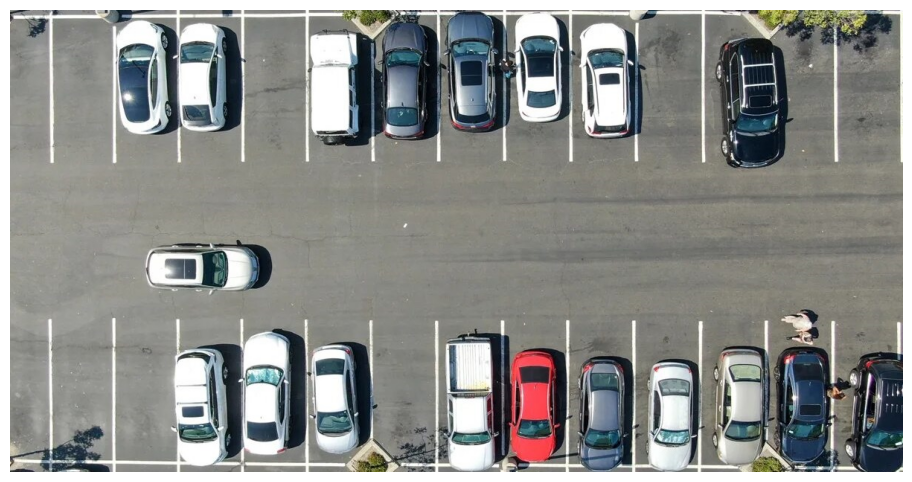

In [15]:
import cv2
import matplotlib.pyplot as plt
import os

image_path = "/content/Parking_Dataset/images/0.png"

print("Exists :", os.path.exists(image_path))

img = cv2.imread(image_path)

print("cv2 Output :", img)

if img is None:
    print("❌ OpenCV image read nahi kar pa raha.")
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12,6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

# Dataset Paths

In [16]:
DATASET_PATH = "/content/Parking_Dataset"

IMAGE_FOLDER = os.path.join(DATASET_PATH, "images")
MASK_FOLDER = os.path.join(DATASET_PATH, "boxes")
XML_PATH = os.path.join(DATASET_PATH, "annotations.xml")
CSV_PATH = os.path.join(DATASET_PATH, "parking.csv")

print("Images :", IMAGE_FOLDER)
print("Masks  :", MASK_FOLDER)
print("XML    :", XML_PATH)
print("CSV    :", CSV_PATH)

Images : /content/Parking_Dataset/images
Masks  : /content/Parking_Dataset/boxes
XML    : /content/Parking_Dataset/annotations.xml
CSV    : /content/Parking_Dataset/parking.csv


# Read XML

In [17]:
tree = ET.parse(XML_PATH)

root = tree.getroot()

images = root.findall("image")

print("Annotated Images :", len(images))

Annotated Images : 30


# Parking Slot Statistics

In [18]:
slot_counts = []

for image in images:
    polygons = image.findall("polygon")
    slot_counts.append(len(polygons))

print("Minimum Slots :", min(slot_counts))
print("Maximum Slots :", max(slot_counts))
print("Average Slots :", round(np.mean(slot_counts), 2))
print("Total Images :", len(slot_counts))
print("Total Parking Slots :", sum(slot_counts))

Minimum Slots : 6
Maximum Slots : 81
Average Slots : 30.1
Total Images : 30
Total Parking Slots : 903


# Visualize Parking Slots Distribution


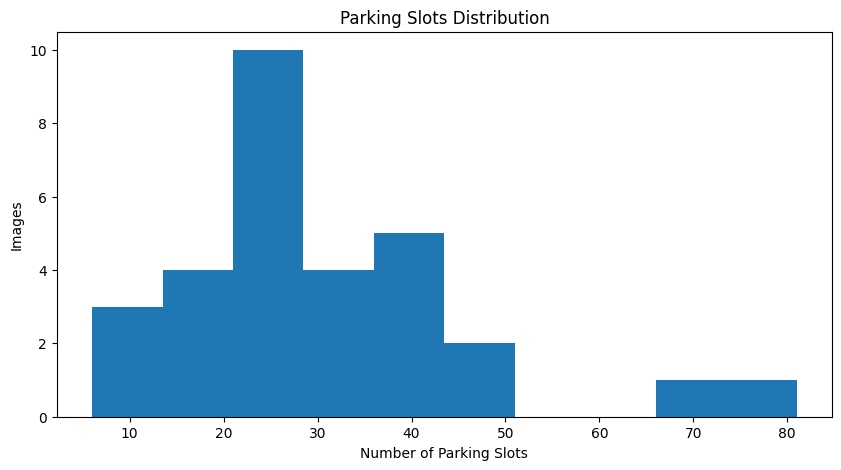

In [19]:
plt.figure(figsize=(10,5))

plt.hist(slot_counts, bins=10)

plt.title("Parking Slots Distribution")

plt.xlabel("Number of Parking Slots")

plt.ylabel("Images")

plt.show()

# Image Resolution Analysis

In [20]:
widths = []
heights = []

for image in images:

    widths.append(int(image.attrib["width"]))

    heights.append(int(image.attrib["height"]))

print("Average Width :", int(np.mean(widths)))
print("Average Height :", int(np.mean(heights)))

print("Minimum Width :", min(widths))
print("Maximum Width :", max(widths))

Average Width : 1177
Average Height : 725
Minimum Width : 477
Maximum Width : 2560


# Read Mask Image

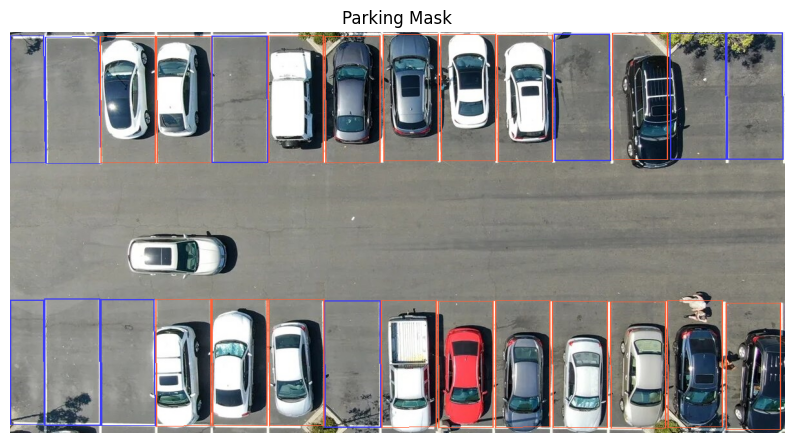

In [21]:
mask_path = os.path.join(MASK_FOLDER, "0.png")

mask = cv2.imread(mask_path)

mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,6))

plt.imshow(mask)

plt.title("Parking Mask")

plt.axis("off")

plt.show()

# Compare Image & Mask

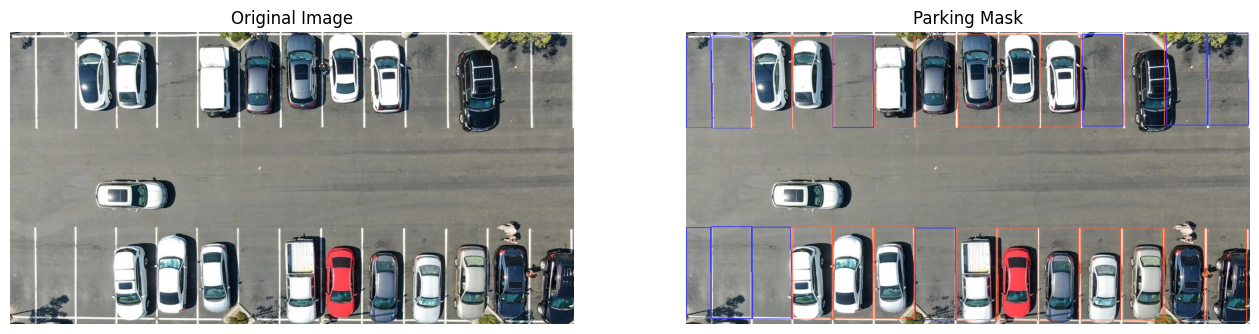

In [22]:
image = cv2.imread(os.path.join(IMAGE_FOLDER, "0.png"))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(os.path.join(MASK_FOLDER, "0.png"))
mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16,6))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask)
plt.title("Parking Mask")
plt.axis("off")

plt.show()

# Resize Function

In [23]:
IMG_SIZE = (640, 640)

def resize_image(image):

    return cv2.resize(image, IMG_SIZE)

# Test Resize

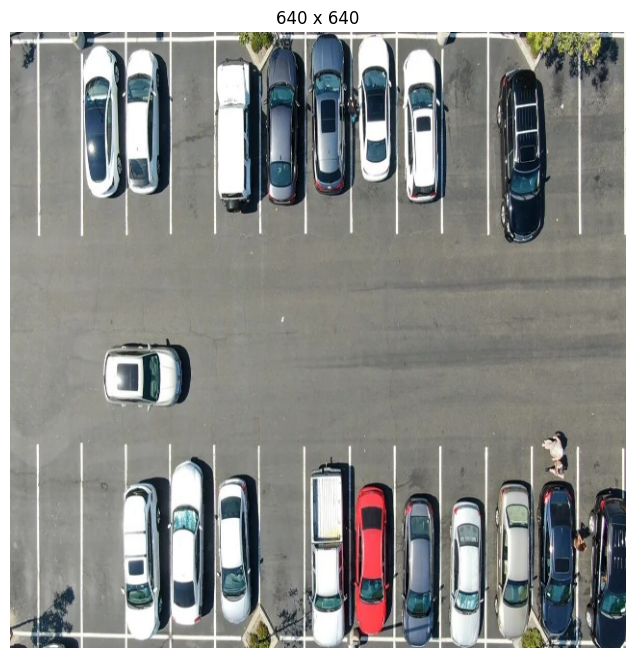

In [24]:
sample = resize_image(image)

plt.figure(figsize=(8,8))

plt.imshow(sample)

plt.title("640 x 640")

plt.axis("off")

plt.show()

# Normalize Image

In [25]:
normalized = sample.astype("float32") / 255.0

print("Min :", normalized.min())
print("Max :", normalized.max())
print("Shape :", normalized.shape)
print("Datatype :", normalized.dtype)

Min : 0.0
Max : 1.0
Shape : (640, 640, 3)
Datatype : float32


# Create Dataset Lists

In [26]:
image_paths = []
mask_paths = []

for _, row in df.iterrows():

    image_paths.append(
        os.path.join(DATASET_PATH, row["image"])
    )

    mask_paths.append(
        os.path.join(DATASET_PATH, row["mask"])
    )

print("Images :", len(image_paths))
print("Masks :", len(mask_paths))

print("\nFirst Image :", image_paths[0])
print("First Mask :", mask_paths[0])

Images : 33
Masks : 33

First Image : /content/Parking_Dataset/images/0.png
First Mask : /content/Parking_Dataset/boxes/0.png


# Create YOLO Folder Structure

In [27]:
folders = [
    "/content/YOLO_Dataset/images/train",
    "/content/YOLO_Dataset/images/valid",
    "/content/YOLO_Dataset/labels/train",
    "/content/YOLO_Dataset/labels/valid"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("✅ YOLO Folder Structure Created Successfully!")

for folder in folders:
    print(folder)

✅ YOLO Folder Structure Created Successfully!
/content/YOLO_Dataset/images/train
/content/YOLO_Dataset/images/valid
/content/YOLO_Dataset/labels/train
/content/YOLO_Dataset/labels/valid


# Read XML Image Information

In [28]:
xml_path = "/content/Parking_Dataset/annotations.xml"

tree = ET.parse(xml_path)
root = tree.getroot()

images = root.findall("image")

print("Total Images :", len(images))

print("\nFirst Image Information:\n")

print(images[0].attrib)

Total Images : 30

First Image Information:

{'id': '0', 'name': 'images/0.png', 'width': '1200', 'height': '621'}


# Read First Parking Polygon

In [29]:
first_image = images[0]

polygons = first_image.findall("polygon")

print("Total Parking Slots :", len(polygons))

print("\nFirst Polygon:\n")

print(polygons[0].attrib)

Total Parking Slots : 28

First Polygon:

{'label': 'free_parking_space', 'occluded': '0', 'source': 'manual', 'points': '54.80,9.10;137.90,7.60;141.12,204.87;55.80,205.70', 'z_order': '0'}


# Polygon ➜ YOLO Bounding Box Function

In [64]:
def polygon_to_yolo(points, img_w, img_h):

    pts = []

    for point in points.split(";"):

        x, y = map(float, point.split(","))

        pts.append([x, y])

    pts = np.array(pts)

    xmin = np.min(pts[:,0])
    xmax = np.max(pts[:,0])

    ymin = np.min(pts[:,1])
    ymax = np.max(pts[:,1])

    x_center = ((xmin + xmax) / 2) / img_w
    y_center = ((ymin + ymax) / 2) / img_h

    width = (xmax - xmin) / img_w
    height = (ymax - ymin) / img_h

    return x_center, y_center, width, height

# Test Conversion

In [65]:
polygon = polygons[0]

x, y, w, h = polygon_to_yolo(
    polygon.attrib["points"],
    int(first_image.attrib["width"]),
    int(first_image.attrib["height"])
)

print("YOLO Coordinates")

print("x_center =", round(x,6))
print("y_center =", round(y,6))
print("width    =", round(w,6))
print("height   =", round(h,6))

YOLO Coordinates
x_center = 0.081633
y_center = 0.171739
width    = 0.071933
height   = 0.319002


# Convert One Image to YOLO Labels

In [66]:
labels = []

for polygon in polygons:

    x, y, w, h = polygon_to_yolo(
        polygon.attrib["points"],
        int(first_image.attrib["width"]),
        int(first_image.attrib["height"])
    )

    labels.append(f"0 {x:.6f} {y:.6f} {w:.6f} {h:.6f}")

print("Total Labels :", len(labels))

print("\nFirst Label:\n")

print(labels[0])

Total Labels : 28

First Label:

0 0.081633 0.171739 0.071933 0.319002


# Convert All XML Annotations to YOLO Labels

In [67]:
label_folder = "/content/YOLO_Dataset/labels/all"
os.makedirs(label_folder, exist_ok=True)

total_files = 0

for image in images:

    image_name = os.path.splitext(
        os.path.basename(image.attrib["name"])
    )[0]

    label_path = os.path.join(label_folder, image_name + ".txt")

    img_w = int(image.attrib["width"])
    img_h = int(image.attrib["height"])

    with open(label_path, "w") as f:

        for polygon in image.findall("polygon"):

            x, y, w, h = polygon_to_yolo(
                polygon.attrib["points"],
                img_w,
                img_h
            )

            # Class 0 = Parking Space
            f.write(f"0 {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")

    total_files += 1

print("✅ YOLO Labels Created Successfully")
print("Total Label Files :", total_files)
print("Saved In :", label_folder)

✅ YOLO Labels Created Successfully
Total Label Files : 30
Saved In : /content/YOLO_Dataset/labels/all


# Check Generated Labels

In [68]:
files = sorted(os.listdir(label_folder))

print("Total TXT Files :", len(files))

print("\nFirst 5 Files:\n")

for file in files[:5]:
    print(file)

Total TXT Files : 30

First 5 Files:

0.txt
1.txt
10.txt
11.txt
12.txt


# Read One Label File

In [69]:
sample_file = os.path.join(label_folder, files[0])

with open(sample_file, "r") as f:

    print(f.read())

0 0.081633 0.171739 0.071933 0.319002
0 0.022462 0.823816 0.044925 0.311079
0 0.023262 0.169944 0.046525 0.318535
0 0.961463 0.162005 0.073192 0.315572
0 0.888008 0.162585 0.073200 0.315572
0 0.738712 0.164887 0.073192 0.315572
0 0.442338 0.828494 0.073192 0.315572
0 0.152313 0.825258 0.070625 0.316538
0 0.080854 0.823382 0.073192 0.315588
0 0.959167 0.834444 0.071617 0.317488
0 0.884025 0.828527 0.071617 0.317472
0 0.810587 0.830507 0.071625 0.317472
0 0.735446 0.829187 0.071625 0.317472
0 0.661667 0.828527 0.071617 0.317472
0 0.587888 0.829187 0.071625 0.317472
0 0.514450 0.828527 0.071617 0.317472
0 0.369608 0.824597 0.071617 0.317472
0 0.296508 0.824597 0.071617 0.317472
0 0.223750 0.825242 0.071617 0.317472
0 0.812904 0.163019 0.071625 0.317472
0 0.664800 0.166965 0.071617 0.317472
0 0.590950 0.165386 0.071617 0.317472
0 0.516696 0.166176 0.071625 0.317472
0 0.442442 0.170113 0.071617 0.317488
0 0.369000 0.169324 0.071617 0.317488
0 0.152054 0.171151 0.071625 0.317472
0 0.224408 0

# Train / Validation Split

In [70]:
import shutil
from sklearn.model_selection import train_test_split

# Image files
image_files = sorted([
    f for f in os.listdir(IMAGE_FOLDER)
    if f.endswith((".png", ".jpg", ".jpeg"))
])

# Split
train_images, valid_images = train_test_split(
    image_files,
    test_size=0.20,
    random_state=42
)

print("Training Images :", len(train_images))
print("Validation Images :", len(valid_images))

Training Images : 24
Validation Images : 6


# Copy Images & Labels

In [71]:
import shutil

train_label_dir = "/content/YOLO_Dataset/labels/train"
valid_label_dir = "/content/YOLO_Dataset/labels/valid"

# Purane labels delete
for folder in [train_label_dir, valid_label_dir]:
    for file in os.listdir(folder):
        os.remove(os.path.join(folder, file))

# Naye labels copy
for img in train_images:
    label = img.replace(".png", ".txt")
    shutil.copy(
        os.path.join(label_folder, label),
        os.path.join(train_label_dir, label)
    )

for img in valid_images:
    label = img.replace(".png", ".txt")
    shutil.copy(
        os.path.join(label_folder, label),
        os.path.join(valid_label_dir, label)
    )

print("✅ Updated Labels Copied Successfully")

✅ Updated Labels Copied Successfully


# Verify Dataset

In [72]:
print("Train Images :", len(os.listdir("/content/YOLO_Dataset/images/train")))
print("Train Labels :", len(os.listdir("/content/YOLO_Dataset/labels/train")))

print()

print("Valid Images :", len(os.listdir("/content/YOLO_Dataset/images/valid")))
print("Valid Labels :", len(os.listdir("/content/YOLO_Dataset/labels/valid")))

Train Images : 24
Train Labels : 24

Valid Images : 6
Valid Labels : 6


# Create data.yaml

In [73]:
%%writefile /content/YOLO_Dataset/data.yaml

train: /content/YOLO_Dataset/images/train
val: /content/YOLO_Dataset/images/valid

nc: 3

names:
  0: free_parking_space
  1: partially_free_parking_space
  2: not_free_parking_space

Overwriting /content/YOLO_Dataset/data.yaml


# Check YAML

In [74]:
with open("/content/YOLO_Dataset/data.yaml") as f:
    print(f.read())


train: /content/YOLO_Dataset/images/train
val: /content/YOLO_Dataset/images/valid

nc: 3

names:
  0: free_parking_space
  1: partially_free_parking_space
  2: not_free_parking_space



In [75]:
!pip install -q ultralytics

In [76]:
from ultralytics import YOLO
import torch

print("Torch Version :", torch.__version__)
print("CUDA Available :", torch.cuda.is_available())

Torch Version : 2.11.0+cu128
CUDA Available : True


# Correct Label Generation

In [82]:
import os

class_map = {
    "free_parking_space": 0,
    "partially_free_parking_space": 1,
    "not_free_parking_space": 2
}

label_folder = "/content/YOLO_Dataset/labels/all"
os.makedirs(label_folder, exist_ok=True)

for image in images:

    image_name = os.path.splitext(
        os.path.basename(image.attrib["name"])
    )[0]

    label_path = os.path.join(label_folder, image_name + ".txt")

    img_w = int(image.attrib["width"])
    img_h = int(image.attrib["height"])

    with open(label_path, "w") as f:

        for polygon in image.findall("polygon"):

            cls = class_map[polygon.attrib["label"]]

            x, y, w, h = polygon_to_yolo(
                polygon.attrib["points"],
                img_w,
                img_h
            )

            f.write(f"{cls} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")

print("✅ Labels Updated Successfully")

✅ Labels Updated Successfully


# Load YOLOv8 Nano Model

In [83]:
model = YOLO("yolov8n.pt")

# Train Model

In [84]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="/content/YOLO_Dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    workers=2,
    device=0,
    project="/content/Parking_Project",
    name="YOLOv8_Parking",
    pretrained=True,
    verbose=True
)

Ultralytics 8.4.103 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/YOLO_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8_Parking-3, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, o

In [85]:
results

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c2ef6491160>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

# Load Best Model

In [86]:
from ultralytics import YOLO

model = YOLO("/content/Parking_Project/YOLOv8_Parking/weights/best.pt")

print("Best Model Loaded Successfully")

Best Model Loaded Successfully


# Predict on One Test Image

In [87]:
results = model.predict(
    source="/content/Parking_Dataset/images/0.png",
    conf=0.25,
    save=True
)


image 1/1 /content/Parking_Dataset/images/0.png: 352x640 27 parking_spaces, 42.2ms
Speed: 2.7ms preprocess, 42.2ms inference, 1.4ms postprocess per image at shape (1, 3, 352, 640)
Results saved to /content/runs/detect/predict


# Show Prediction

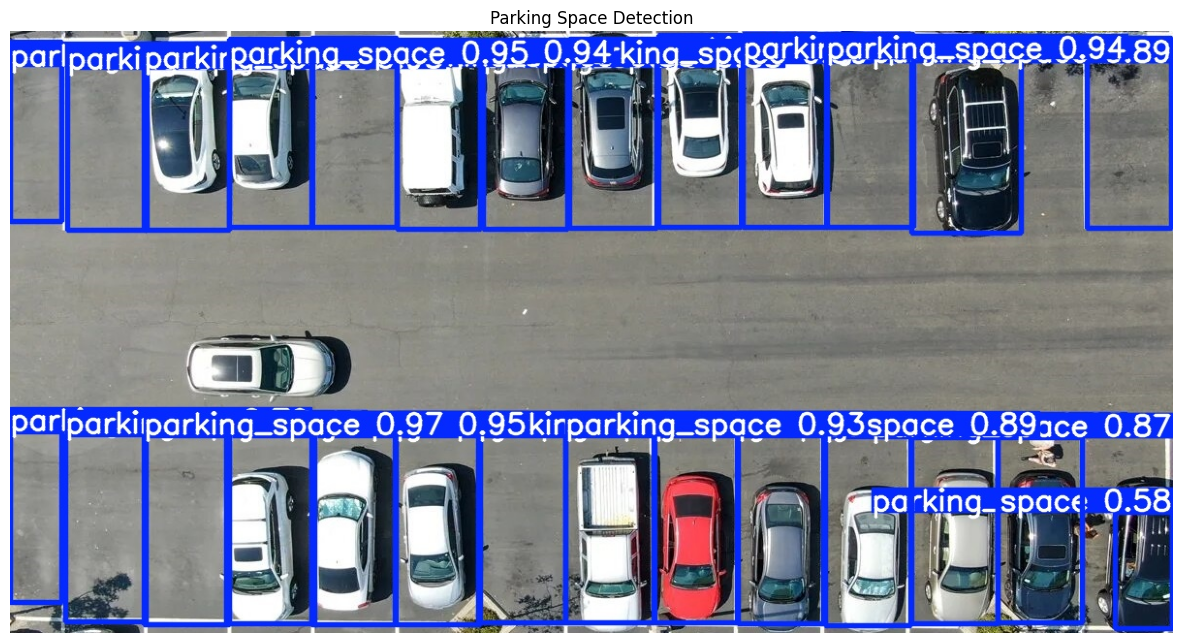

In [93]:
prediction_path = "/content/runs/detect/predict/0.jpg"

img = cv2.imread(prediction_path)

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15,8))
plt.imshow(img)
plt.axis("off")
plt.title("Parking Space Detection")
plt.show()

In [94]:
model = YOLO("/content/Parking_Project/YOLOv8_Parking/weights/best.pt")

results = model.predict(
    source="/content/Parking_Dataset/images/0.png",
    conf=0.25,
    save=False
)

print("Detected Objects:", len(results[0].boxes))

for box in results[0].boxes:
    cls = int(box.cls[0])
    conf = float(box.conf[0])

    print(f"{model.names[cls]}  |  Confidence: {conf:.2f}")


image 1/1 /content/Parking_Dataset/images/0.png: 352x640 27 parking_spaces, 19.4ms
Speed: 5.1ms preprocess, 19.4ms inference, 4.7ms postprocess per image at shape (1, 3, 352, 640)
Detected Objects: 27
parking_space  |  Confidence: 0.97
parking_space  |  Confidence: 0.95
parking_space  |  Confidence: 0.95
parking_space  |  Confidence: 0.94
parking_space  |  Confidence: 0.94
parking_space  |  Confidence: 0.93
parking_space  |  Confidence: 0.93
parking_space  |  Confidence: 0.93
parking_space  |  Confidence: 0.92
parking_space  |  Confidence: 0.92
parking_space  |  Confidence: 0.91
parking_space  |  Confidence: 0.90
parking_space  |  Confidence: 0.90
parking_space  |  Confidence: 0.89
parking_space  |  Confidence: 0.89
parking_space  |  Confidence: 0.89
parking_space  |  Confidence: 0.87
parking_space  |  Confidence: 0.86
parking_space  |  Confidence: 0.85
parking_space  |  Confidence: 0.85
parking_space  |  Confidence: 0.83
parking_space  |  Confidence: 0.82
parking_space  |  Confidence

In [95]:
from ultralytics import YOLO

model = YOLO("/content/Parking_Project/YOLOv8_Parking/weights/best.pt")

print(model.names)

{0: 'parking_space'}
